# Detección de defectos en infraestructuras (`Corrosion-bi3q3`) con RetinaNet v2

**Asignatura:** Visión por Computador — Grado en Inteligencia Artificial (USC, 2026/2027)  
**Dataset asignado:** `Francesco/corrosion-bi3q3` (Roboflow-100)  
**Detector analizado:** RetinaNet v2 (`retinanet_resnet50_fpn_v2`, pesos `COCO_V1` de `torchvision`)

Este notebook sirve para **visualizar y comparar resultados**, no para entrenar modelos:
1. Descripción del dataset y de **RetinaNet v2**.
2. Metodología y curvas del **baseline** (pérdidas y mAP de validación).
3. **Estrategias de mejora**: hipótesis y configuraciones evaluadas.
4. **Comparación cuantitativa sobre validación** para elegir modelos sin utilizar test.
5. **Análisis cualitativo** y comparación de inferencia con y sin TTA en validación.
6. Preparación del **ensemble con Faster R-CNN v2**.
7. **Evaluación final en test**, una vez elegidos los modelos.



In [47]:
import json
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from matplotlib.patches import Rectangle
from IPython.display import display

# Localizar la raíz del proyecto tanto desde la raíz como desde notebooks/.
RAIZ = Path.cwd()
if not (RAIZ / "src").exists():
    RAIZ = RAIZ.parent
if not (RAIZ / "src").exists():
    raise FileNotFoundError("Abre el notebook desde la raíz del repositorio o desde notebooks/.")
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

from src.dataset import CorrosionDataset, NOMBRES_CLASES, PARTICIONES
from src.evaluar import cargar_predicciones, _iou_entre_cajas

DIR_RESULTADOS = RAIZ / "results" / "slippage_validation_split"
DIR_FIGURAS = DIR_RESULTADOS / "figuras_retinanet"
DIR_FIGURAS.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 200,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 10,
})

COLORES_CLASE = {
    1: "#1f77b4",  # Slippage
    2: "#d62728",  # corrosion
    3: "#ff7f0e",  # crack
}

print(f"Raíz del proyecto: {RAIZ}")
print(f"Figuras: {DIR_FIGURAS}")
print(f"CUDA disponible: {torch.cuda.is_available()} (no es necesaria para analizar resultados guardados)")


Raíz del proyecto: /home/lucas/IA/Vision/deteccion-corrosion
Figuras: /home/lucas/IA/Vision/deteccion-corrosion/results/slippage_validation_split/figuras_retinanet
CUDA disponible: True (no es necesaria para analizar resultados guardados)


---
## 1. Descripción del dataset (`Corrosion-bi3q3`) y del modelo RetinaNet v2

Por indicación del profesor, se trasladaron 20 imágenes completas con `Slippage` del entrenamiento original a validación. Ambos detectores usan la misma división corregida. Hay que reentrenar ambos modelos para obtener resultados con esta división. [Manifiesto](../configs/particiones/slippage_validation_split.json)

### Particularidades del dataset
- **Resolución:** imágenes de `640 × 640` píxeles. Particiones: `train=820`, `validation=125`, `test=304`; hay imágenes sin objetos anotados (`37 / 5 / 13`).
- **Clases:** `1=Slippage`, `2=corrosion`, `3=crack`; el índice `0` queda reservado y no hay anotaciones de la categoría original `corrosion-0`.
- **Desequilibrio de clases.** En `train` hay 499 anotaciones de `Slippage`, 1.175 de `corrosion` y 1.388 de `crack`. En `validation` hay 49, 165 y 258, respectivamente.
- **Objetos pequeños:** aproximadamente el `85,2 %` de las anotaciones tienen un área inferior a `32²=1024 px²`. Es una posible motivación para probar mayor resolución o anchors adaptados.

### Arquitectura: RetinaNet v2 (`ResNet-50 + FPN v2`)
- Detector **de una etapa (*one-stage*)**: predice clases y cajas directamente sobre una pirámide multiescala de características, sin la fase de propuestas/RoI de Faster R-CNN.
- **Backbone ResNet-50 + FPN** y cabeza de clasificación/regresión; parte de los pesos `RetinaNet_ResNet50_FPN_V2_Weights.COCO_V1` de torchvision.
- **Clasificación por ancla:** utiliza una clasificación sigmoide con pérdida focal, a diferencia del *softmax* de Faster R-CNN. En nuestra adaptación se reservan 4 índices (`0` sin anotaciones, `1..3` defectos) y se generan **9 × 4 = 36 logits** por posición de la cabeza de clasificación.
- Se conserva la cabeza de regresión, GroupNorm y los anchors por defecto para establecer un baseline comparable. Las modificaciones de anchors o resolución se plantearán como experimentos posteriores.

Las figuras siguientes caracterizan el dataset; no dependen de ningún entrenamiento.


,Partición,Imágenes,Sin objetos,Slippage,corrosion,crack,Total objetos
0,train,820,37,499,1175,1388,3062
1,validation,125,5,49,165,258,472
2,test,304,13,98,317,867,1282


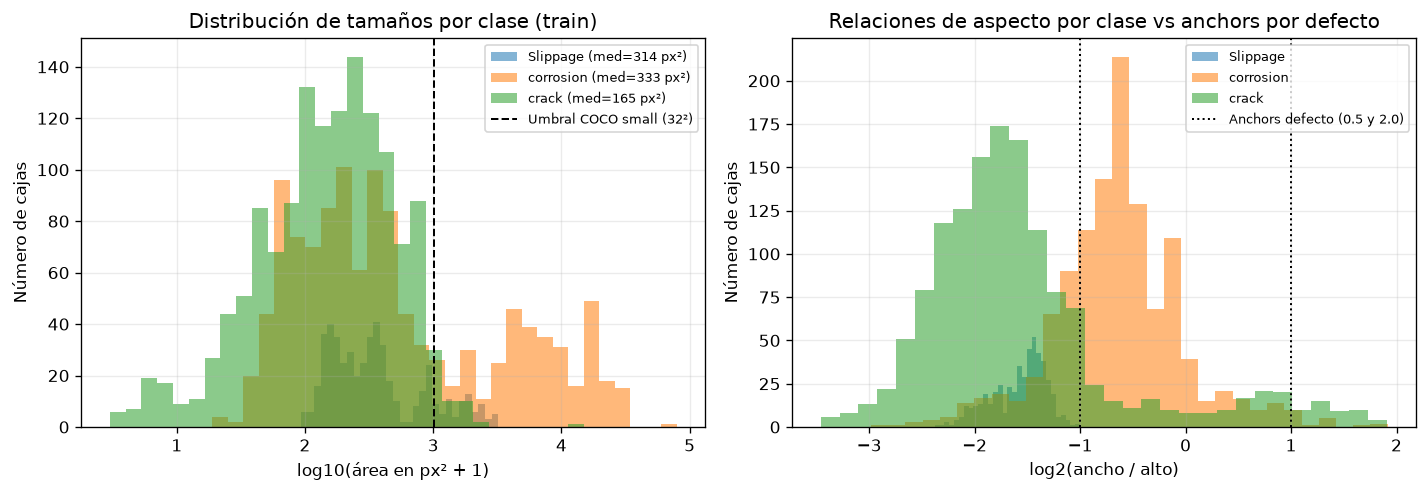

In [48]:
# Análisis cuantitativo de clases, tamaños y relaciones de aspecto (motivación de mejoras)

ruta_dataset = RAIZ / "data" / "corrosion-bi3q3"
if not ruta_dataset.exists():
    print("Dataset no encontrado. Ejecuta: uv run python scripts/descargar_datos.py")
else:
    datos_hf = {particion: CorrosionDataset(particion).datos for particion in PARTICIONES}

    filas_resumen = []
    ratios_por_clase = {nombre: [] for nombre in NOMBRES_CLASES.values()}
    areas_por_clase = {nombre: [] for nombre in NOMBRES_CLASES.values()}

    for particion, datos in datos_hf.items():
        cont = Counter()
        vacias = 0
        for objetos in datos["objects"]:
            cajas = objetos["bbox"]
            cats = objetos["category"]
            if len(cajas) == 0:
                vacias += 1
            cont.update(cats)
            if particion == "train":
                for (x, y, w, h), cat in zip(cajas, cats):
                    nombre = NOMBRES_CLASES[cat]
                    areas_por_clase[nombre].append(w * h)
                    ratios_por_clase[nombre].append(w / max(h, 1e-6))

        filas_resumen.append({
            "Partición": particion,
            "Imágenes": len(datos),
            "Sin objetos": vacias,
            "Slippage": cont.get(1, 0),
            "corrosion": cont.get(2, 0),
            "crack": cont.get(3, 0),
            "Total objetos": sum(cont.values()),
        })

    df_dataset = pd.DataFrame(filas_resumen)
    display(df_dataset)

    # Gráfica de distribución de áreas y relaciones de aspecto por clase en train
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

    for nombre, areas in areas_por_clase.items():
        axes[0].hist(np.log10(np.asarray(areas) + 1), bins=30, alpha=0.55, label=f"{nombre} (med={np.median(areas):.0f} px²)")
    axes[0].axvline(np.log10(32**2), color="black", linestyle="--", linewidth=1.2, label="Umbral COCO small (32²)")
    axes[0].set_xlabel("log10(área en px² + 1)")
    axes[0].set_ylabel("Número de cajas")
    axes[0].set_title("Distribución de tamaños por clase (train)")
    axes[0].legend(fontsize=8)

    for nombre, ratios in ratios_por_clase.items():
        axes[1].hist(np.log2(np.asarray(ratios)), bins=30, alpha=0.55, label=nombre)
    axes[1].axvline(np.log2(0.5), color="black", linestyle=":", linewidth=1.2, label="Anchors defecto (0.5 y 2.0)")
    axes[1].axvline(np.log2(2.0), color="black", linestyle=":", linewidth=1.2)
    axes[1].set_xlabel("log2(ancho / alto)")
    axes[1].set_ylabel("Número de cajas")
    axes[1].set_title("Relaciones de aspecto por clase vs anchors por defecto")
    axes[1].legend(fontsize=8)

    plt.tight_layout()
    plt.savefig(DIR_FIGURAS / "01_eda_tamanos_aspecto_retinanet.png", bbox_inches="tight")
    plt.show()


### Análisis de la distribución de los objetos

El dataset presenta un claro predominio de objetos pequeños. La clase `crack` tiene la menor mediana de área (**165 px²**), seguida de `Slippage` (**314 px²**) y `corrosion` (**333 px²**). Una proporción importante de las cajas se encuentra por debajo del umbral de objetos pequeños de COCO (32 × 32 píxeles).

En cuanto a las relaciones de aspecto, las grietas presentan una distribución especialmente alargada, con numerosas cajas cuya relación ancho/alto es inferior a 0,5. Esto podría dificultar su detección con los anchors predeterminados.

**Implicaciones:** estas características justifican experimentar posteriormente con una mayor resolución de entrada y con anchors adaptados a objetos pequeños y alargados.

---
## 2. Metodología y resultados del baseline

### Configuración (`configs/retinanet.yaml`)
- **Modelo:** `retinanet_resnet50_fpn_v2` preentrenado en COCO, con la última convolución de clasificación adaptada a 4 índices (`0..3`), `capas_entrenables_backbone=3` y resolución interna `min_size=800`, `max_size=1333`.
- **Entrenamiento:** 12 épocas, AdamW (`lr=1e-4`, `weight_decay=1e-4`), `batch_size=2`, acumulación de gradientes (`4 pasos`), semilla `42` y AMP si hay CUDA. El resto de los parámetros se toma del YAML.
- **Selección:** se guarda el mejor checkpoint según **mAP@[0.50:0.95] en `validation`**. **No se utiliza `test` para elegir estrategias.**

Para entrenar fuera de este notebook:

```bash
uv run --locked python -m src.entrenar --config configs/retinanet.yaml --sin-test
```

Esto genera `results/slippage_validation_split/retinanet/historial.json`, `mejor_modelo.pth` y `ultimo_modelo.pth` (entre otros archivos). Después, **si se quieren curvas PR, AP por clase y latencia en validación**, ejecutar:

```bash
uv run --locked python -m src.evaluar --checkpoint results/slippage_validation_split/retinanet/mejor_modelo.pth --particion validation --guardar results/slippage_validation_split/retinanet/metricas_validation.json --guardar-preds results/slippage_validation_split/retinanet/predicciones_validation.json
```

El notebook lee estos archivos cuando existan, sin volver a entrenar ni cargar el modelo en GPU.


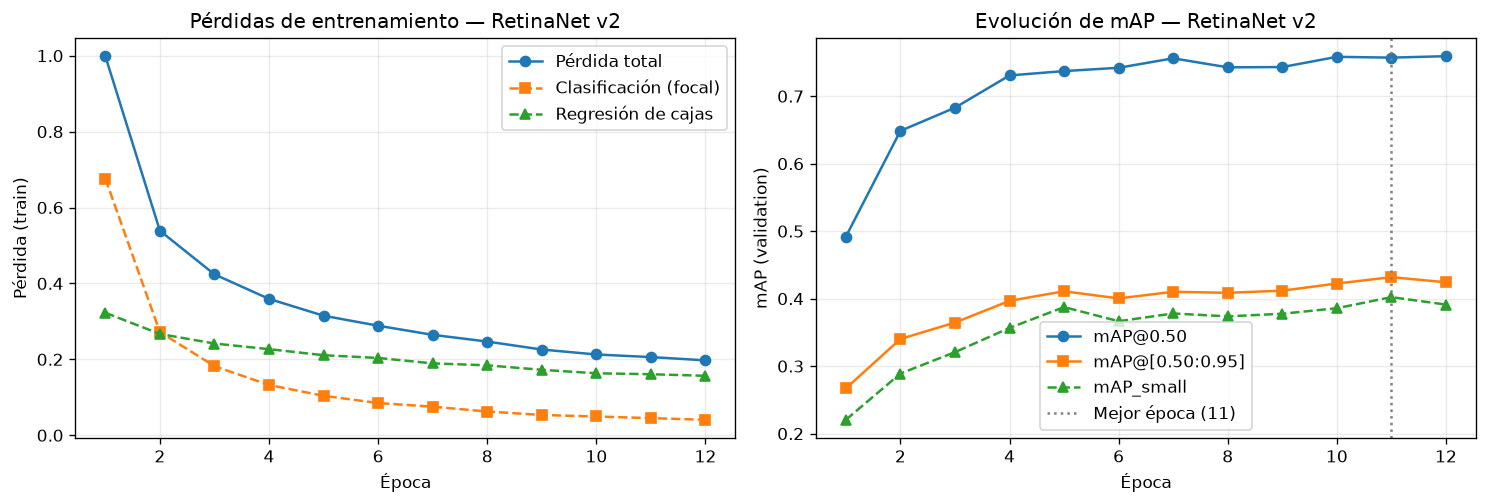

In [49]:
# Registro de experimentos: nombre legible -> carpeta de resultados.
NOMBRE_BASELINE = "Baseline (RetinaNet v2)"
EXPERIMENTOS = {
    NOMBRE_BASELINE: {
        "dir": DIR_RESULTADOS / "retinanet",
        "categoria": "Baseline",
        "hipotesis": "RetinaNet v2 COCO_V1, AdamW, 800 px y anchors por defecto.",
    },
    "E1: Aumento de datos": {
        "dir": DIR_RESULTADOS / "retinanet_exp01_aumentos",
        "categoria": "Aumentos",
        "hipotesis": "Volteos y variaciones de color para mejorar la generalización.",
    },
    "E2: 960 px · 12 épocas": {
        "dir": DIR_RESULTADOS / "retinanet_exp02_resolucion",
        "categoria": "Resolución",
        "hipotesis": "Evaluar mayor resolución interna para objetos pequeños.",
    },
    "E2: 960 px · 20 épocas": {
        "dir": DIR_RESULTADOS / "retinanet_exp02_resolucion_20ep",
        "categoria": "Resolución",
        "hipotesis": "Comprobar si más épocas mejoran el mAP a 960 px.",
    },
    "E3: SGD con momentum": {
        "dir": DIR_RESULTADOS / "retinanet_exp03_sgd",
        "categoria": "Optimización",
        "hipotesis": "Comparar SGD + momentum frente a AdamW.",
    },
}


def leer_json(ruta: Path) -> dict | list | None:
    if not ruta.exists():
        return None
    with ruta.open(encoding="utf-8") as archivo:
        return json.load(archivo)


def cargar_historial_experimento(dir_exp: Path) -> list[dict] | None:
    datos = leer_json(dir_exp / "historial.json")
    return datos if isinstance(datos, list) else None


def cargar_metricas_experimento(dir_exp: Path, particion: str = "validation") -> dict | None:
    """Carga métricas detalladas o, en validación, las del mejor registro del historial."""
    ruta = dir_exp / f"metricas_{particion}.json"
    datos = leer_json(ruta)
    if isinstance(datos, dict):
        if particion in datos and isinstance(datos[particion], dict):
            return datos[particion]  # train.py envuelve así metricas_test.json
        if "map" in datos:
            return datos  # evaluar.py guarda directamente el diccionario
    if particion == "validation":
        historial = cargar_historial_experimento(dir_exp)
        if historial:
            registros = [h.get("metricas_val", {}) for h in historial]
            registros = [m for m in registros if isinstance(m, dict) and "map" in m]
            if registros:
                return max(registros, key=lambda m: m["map"])
    return None


# Curvas de entrenamiento del baseline: claves propias de RetinaNet.
hist_base = cargar_historial_experimento(EXPERIMENTOS[NOMBRE_BASELINE]["dir"])
if hist_base:
    epocas = [h["epoca"] for h in hist_base]
    perdida_total = [h["perdidas_train"].get("total", np.nan) for h in hist_base]
    perdida_cls = [h["perdidas_train"].get("classification", np.nan) for h in hist_base]
    perdida_cajas = [h["perdidas_train"].get("bbox_regression", np.nan) for h in hist_base]
    val_map = [h["metricas_val"]["map"] for h in hist_base]
    val_map50 = [h["metricas_val"]["map_50"] for h in hist_base]
    val_small = [h["metricas_val"].get("map_small", np.nan) for h in hist_base]

    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3))
    axes[0].plot(epocas, perdida_total, marker="o", label="Pérdida total")
    axes[0].plot(epocas, perdida_cls, marker="s", linestyle="--", label="Clasificación (focal)")
    axes[0].plot(epocas, perdida_cajas, marker="^", linestyle="--", label="Regresión de cajas")
    axes[0].set_xlabel("Época")
    axes[0].set_ylabel("Pérdida (train)")
    axes[0].set_title("Pérdidas de entrenamiento — RetinaNet v2")
    axes[0].legend()

    axes[1].plot(epocas, val_map50, marker="o", label="mAP@0.50")
    axes[1].plot(epocas, val_map, marker="s", label="mAP@[0.50:0.95]")
    axes[1].plot(epocas, val_small, marker="^", linestyle="--", label="mAP_small")
    mejor_idx = int(np.nanargmax(val_map))
    axes[1].axvline(epocas[mejor_idx], color="gray", linestyle=":", label=f"Mejor época ({epocas[mejor_idx]})")
    axes[1].set_xlabel("Época")
    axes[1].set_ylabel("mAP (validation)")
    axes[1].set_title("Evolución de mAP — RetinaNet v2")
    axes[1].legend()

    plt.tight_layout()
    plt.savefig(DIR_FIGURAS / "02_baseline_curvas_entrenamiento.png", bbox_inches="tight")
    plt.show()
else:
    print("Aún no existe results/slippage_validation_split/retinanet/historial.json. Ejecuta primero el baseline.")


### Análisis de la evolución del entrenamiento

Las pérdidas de clasificación y regresión disminuyen progresivamente durante las 12 épocas. La pérdida total pasa aproximadamente de **1,00 a 0,20**, lo que indica que el modelo consigue optimizar ambas tareas.

El mAP de validación mejora rápidamente durante las primeras épocas y comienza a estabilizarse a partir de la quinta. El mejor resultado se alcanza en la **época 11**, con un **mAP@[0.50:0.95] de 0,4318**.

Aunque la pérdida de entrenamiento continúa disminuyendo, el rendimiento en validación apenas cambia durante las últimas épocas. Esto sugiere que el modelo ha alcanzado una meseta de rendimiento, sin evidencias claras de sobreajuste pronunciado.

**Conclusión:** RetinaNet presenta una convergencia estable. Se conserva el checkpoint de la época 11 para las evaluaciones posteriores.

=== RetinaNet baseline: validación ===
mAP@[0.50:0.95]: 0.4319 | mAP@0.50: 0.7572
mAP_small: 0.4023
Latencia: 26.84 ms/img (37.26 FPS)


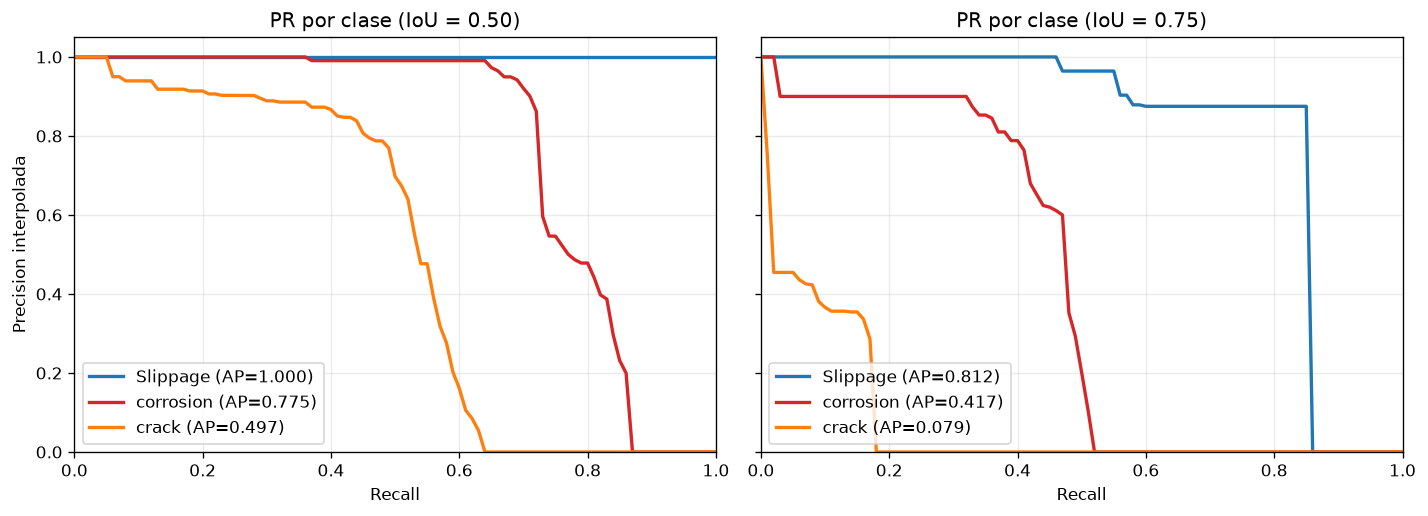

In [50]:
# Curvas precisión-recall y resumen del baseline en VALIDACIÓN.
met_base = cargar_metricas_experimento(EXPERIMENTOS[NOMBRE_BASELINE]["dir"], "validation")

if met_base:
    print("=== RetinaNet baseline: validación ===")
    print(f"mAP@[0.50:0.95]: {met_base['map']:.4f} | mAP@0.50: {met_base['map_50']:.4f}")
    if "map_small" in met_base:
        print(f"mAP_small: {met_base['map_small']:.4f}")
    if "tiempos" in met_base:
        t = met_base["tiempos"]
        print(f"Latencia: {t['ms_por_imagen']:.2f} ms/img ({t['fps']:.2f} FPS)")

    if "curvas_pr_50" in met_base:
        fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
        for ax, clave, titulo in [
            (axes[0], "curvas_pr_50", "PR por clase (IoU = 0.50)"),
            (axes[1], "curvas_pr_75", "PR por clase (IoU = 0.75)"),
        ]:
            curvas = met_base.get(clave, {})
            for id_c, nombre in NOMBRES_CLASES.items():
                c = curvas.get(nombre)
                if c and c.get("n_gt", 0) > 0 and len(c.get("recall", [])) > 0:
                    ax.plot(c["recall"], c["precision_interp"], linewidth=2,
                            color=COLORES_CLASE[id_c], label=f"{nombre} (AP={c['ap']:.3f})")
            ax.set_xlim(0, 1)
            ax.set_ylim(0, 1.05)
            ax.set_xlabel("Recall")
            ax.set_title(titulo)
            if ax.lines:
                ax.legend(loc="lower left")
        axes[0].set_ylabel("Precision interpolada")
        plt.tight_layout()
        plt.savefig(DIR_FIGURAS / "03_baseline_curvas_pr_validation.png", bbox_inches="tight")
        plt.show()
    else:
        print("Para obtener curvas PR y tiempos, evalúa el checkpoint sobre validation:")
        print("uv run --locked python -m src.evaluar --checkpoint results/slippage_validation_split/retinanet/mejor_modelo.pth "
              "--particion validation --guardar results/slippage_validation_split/retinanet/metricas_validation.json "
              "--guardar-preds results/slippage_validation_split/retinanet/predicciones_validation.json")
else:
    print("Todavía no se encontraron métricas de validación para RetinaNet.")


### Análisis de las curvas precisión-recall

Las curvas PR muestran diferencias importantes en el rendimiento de RetinaNet según la clase y el umbral de IoU utilizado.

Con **IoU = 0,50**, `Slippage` alcanza un AP de **1,000**, manteniendo una precisión prácticamente perfecta. `corrosion` obtiene un AP de **0,775**, aunque su precisión disminuye al aumentar el recall. Por su parte, `crack` presenta el peor rendimiento (AP = **0,497**), con una caída pronunciada de precisión a partir de un recall cercano a 0,5.

Al aumentar el umbral a **IoU = 0,75**, los resultados empeoran considerablemente:

- **Slippage:** AP = 0,812.
- **corrosion:** AP = 0,417.
- **crack:** AP = 0,079.

Esta caída es especialmente acusada en `crack`, lo que indica que el modelo tiene dificultades para localizar con precisión las grietas, incluso cuando consigue detectarlas con un criterio de IoU menos exigente.

**Conclusión:** la localización de las grietas constituye una de las principales limitaciones del baseline. Su reducido tamaño y sus relaciones de aspecto extremas podrían contribuir a este problema, lo que justifica experimentar con mayores resoluciones y anchors adaptados.

El resultado de `Slippage` debe interpretarse con cautela, ya que únicamente existen 49 anotaciones de esta clase en validación.

---
## 3. Diseño de los experimentos

E1, E2 y E3 parten de los mismos pesos preentrenados de COCO y usan el reparto corregido, la semilla 42 y 12 épocas. Cada variante se compara con el baseline de 800 px. Se guarda el checkpoint que maximiza el mAP@[0,50:0,95] en validación.

| Estrategia | Cambio evaluado | Hipótesis |
|---|---|---|
| **E1 · Aumento de datos** | Volteos horizontal y vertical, recortes con zoom y variaciones de color. | El conjunto de aumentos puede mejorar la generalización ante cambios de orientación, escala e iluminación. |
| **E2 · Mayor resolución** | Se aumenta el tamaño mínimo interno de 800 a 960 px. | Una entrada mayor puede facilitar la localización de defectos pequeños. |
| **E2 · 20 épocas** | Se repite E2 desde los pesos COCO con 20 épocas. El scheduler coseno se ajusta a esa duración. | El mejor checkpoint de la variante corta se obtuvo en la época 12. Un entrenamiento más largo podría mejorar el mAP. |
| **E3 · SGD** | Se usa SGD con momentum de 0,9 y una tasa de aprendizaje de 0,005. Se mantiene el scheduler coseno. | Esta configuración de optimización podría mejorar la generalización frente a AdamW. |
| **E5 · TTA con WBF** | El checkpoint seleccionado procesa la imagen original y su volteo horizontal. Se fusionan ambas predicciones durante la inferencia. | La segunda vista puede mejorar la detección y la localización. |

E4, la adaptación de anchors, queda como propuesta. La selección de configuraciones se hace en validación y la evaluación final se reserva para `test`.


---
## 4. Comparación de los entrenamientos en validación

El mAP@[0,50:0,95] determina el orden de los checkpoints. El mAP@0,50, el mAP de objetos pequeños y el AP por clase ayudan a identificar de dónde viene cada cambio. La tabla y la gráfica de latencia usan las evaluaciones detalladas de una sola vista con lotes de cuatro imágenes. La comparación de TTA de la sección 5 usa su propio protocolo de tiempos.


Comparativa en validación:


,Experimento,Categoría,mAP@0.50:0.95,ΔmAP vs Base,mAP@0.50,mAP_small,AP Slippage,AP corrosion,AP crack,ms/img,FPS
0,Baseline (RetinaNet v2),Baseline,0.4319,0.0000,0.7572,0.4023,0.6721,0.4464,0.1771,26.84,37.26
1,E1: Aumento de datos,Aumentos,0.4221,-0.0098,0.7506,0.3992,0.6218,0.4805,0.1641,26.23,38.13
2,E2: 960 px · 12 épocas,Resolución,0.4497,0.0178,0.7652,0.4263,0.6646,0.4824,0.2021,35.81,27.93
3,E2: 960 px · 20 épocas,Resolución,0.4597,0.0278,0.7606,0.4376,0.6840,0.4862,0.2089,34.84,28.70
4,E3: SGD con momentum,Optimización,0.3985,-0.0334,0.7138,0.3653,0.6256,0.4307,0.1393,26.91,37.16


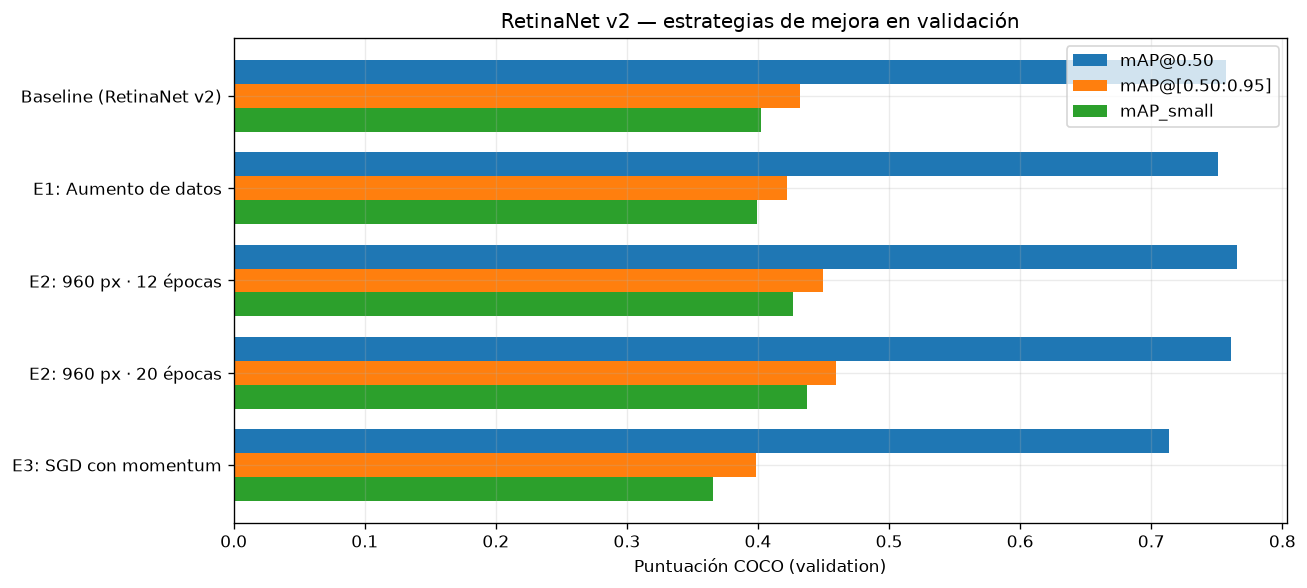

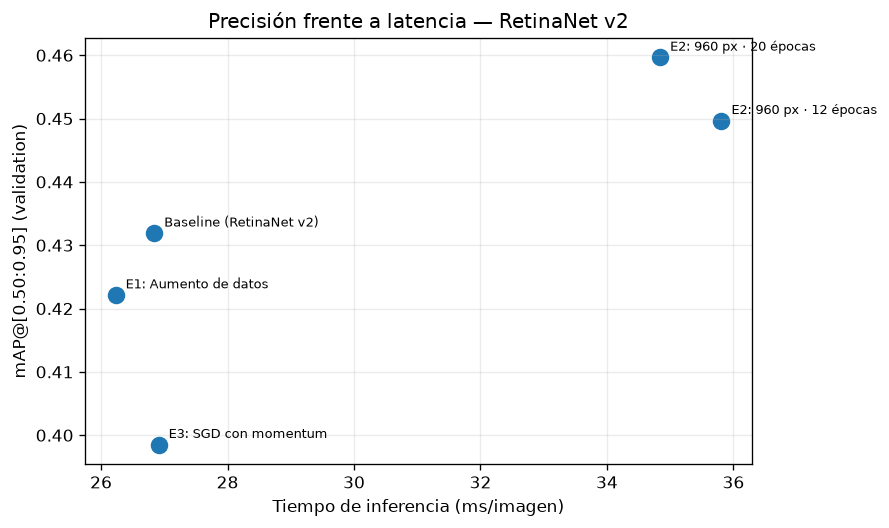

In [51]:
filas_comp = []
metricas_por_exp = {}

for nombre, meta in EXPERIMENTOS.items():
    m = cargar_metricas_experimento(meta["dir"], "validation")
    if not m:
        continue
    metricas_por_exp[nombre] = m
    ap_clase = m.get("map_por_clase", {})
    tiempos = m.get("tiempos", {})
    filas_comp.append({
        "Experimento": nombre,
        "Categoría": meta["categoria"],
        "mAP@0.50:0.95": m.get("map", np.nan),
        "mAP@0.50": m.get("map_50", np.nan),
        "mAP_small": m.get("map_small", np.nan),
        "AP Slippage": ap_clase.get("Slippage", np.nan),
        "AP corrosion": ap_clase.get("corrosion", np.nan),
        "AP crack": ap_clase.get("crack", np.nan),
        "ms/img": tiempos.get("ms_por_imagen", np.nan),
        "FPS": tiempos.get("fps", np.nan),
    })

if filas_comp:
    df_comp = pd.DataFrame(filas_comp)
    base = metricas_por_exp.get(NOMBRE_BASELINE)
    referencia = base["map"] if base is not None else np.nan
    df_comp.insert(3, "ΔmAP vs Base", df_comp["mAP@0.50:0.95"] - referencia)
    print("Comparativa en validación:")
    display(df_comp.round(4))

    fig, ax = plt.subplots(figsize=(11, max(3.5, 0.7 * len(df_comp) + 1.5)))
    y = np.arange(len(df_comp))
    alto = 0.26
    ax.barh(y - alto, df_comp["mAP@0.50"], height=alto, label="mAP@0.50")
    ax.barh(y, df_comp["mAP@0.50:0.95"], height=alto, label="mAP@[0.50:0.95]")
    ax.barh(y + alto, df_comp["mAP_small"], height=alto, label="mAP_small")
    ax.set_yticks(y)
    ax.set_yticklabels(df_comp["Experimento"])
    ax.invert_yaxis()
    ax.set_xlabel("Puntuación COCO (validation)")
    ax.set_title("RetinaNet v2 — estrategias de mejora en validación")
    ax.legend()
    plt.tight_layout()
    plt.savefig(DIR_FIGURAS / "04_comparativa_validacion.png", bbox_inches="tight")
    plt.show()

    df_lat = df_comp.dropna(subset=["ms/img"])
    if not df_lat.empty:
        fig, ax = plt.subplots(figsize=(7.5, 4.5))
        ax.scatter(df_lat["ms/img"], df_lat["mAP@0.50:0.95"], s=90)
        for _, fila in df_lat.iterrows():
            ax.annotate(fila["Experimento"], (fila["ms/img"], fila["mAP@0.50:0.95"]),
                        xytext=(6, 4), textcoords="offset points", fontsize=8)
        ax.set_xlabel("Tiempo de inferencia (ms/imagen)")
        ax.set_ylabel("mAP@[0.50:0.95] (validation)")
        ax.set_title("Precisión frente a latencia — RetinaNet v2")
        plt.tight_layout()
        plt.savefig(DIR_FIGURAS / "05_tradeoff_latencia_validation.png", bbox_inches="tight")
        plt.show()
else:
    print("Aún no hay métricas de validación. Ejecuta el baseline y vuelve a abrir el notebook.")


### Efecto de cada estrategia

- **E1 · Aumentos.** El AP de `corrosion` sube de 0,4464 a 0,4805. El AP de las otras dos clases cae y el mAP global pasa de 0,4319 a 0,4221. El resultado corresponde al conjunto de transformaciones evaluado.
- **E2 · Resolución.** A 960 px y 12 épocas, el mAP sube a 0,4497 y el de objetos pequeños pasa de 0,4023 a 0,4263. La latencia medida aumenta de 26,84 a 35,81 ms por imagen.
- **E2 · 20 épocas.** El mejor checkpoint se guardó en la **época 13**. Alcanzó **0,4597 de mAP** y **0,4376 en objetos pequeños**, aproximadamente 1,00 y 1,13 puntos por encima de E2 con 12 épocas. Su tamaño de entrada sigue siendo 960 px y su latencia medida fue de 34,84 ms por imagen.
- **E3 · SGD.** La configuración probada queda en 0,3985 de mAP, 3,34 puntos por debajo del baseline con AdamW.

Mejor configuración en validation: E2: 960 px · 20 épocas (mAP=0.4597)


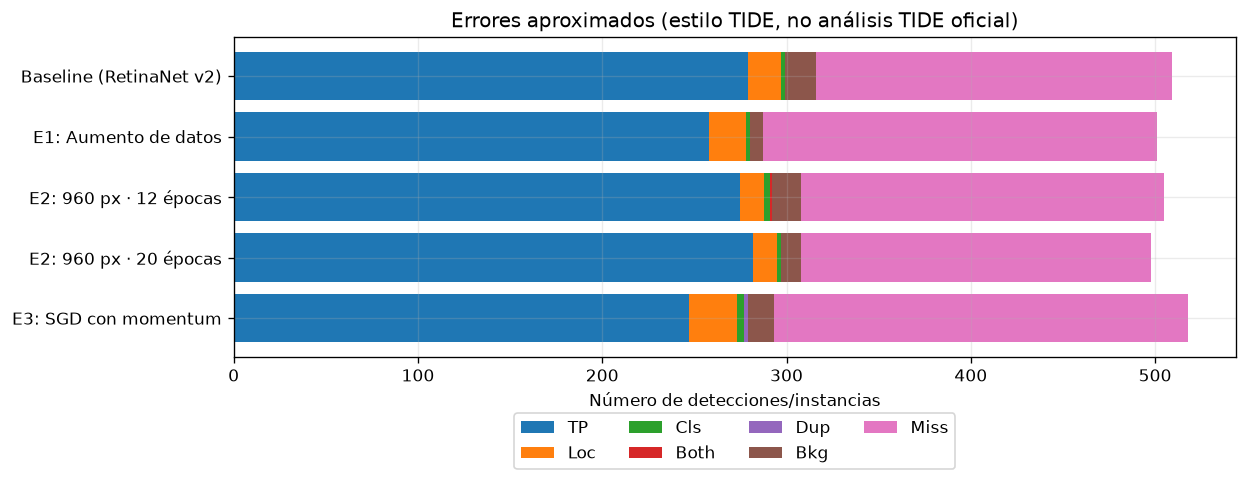

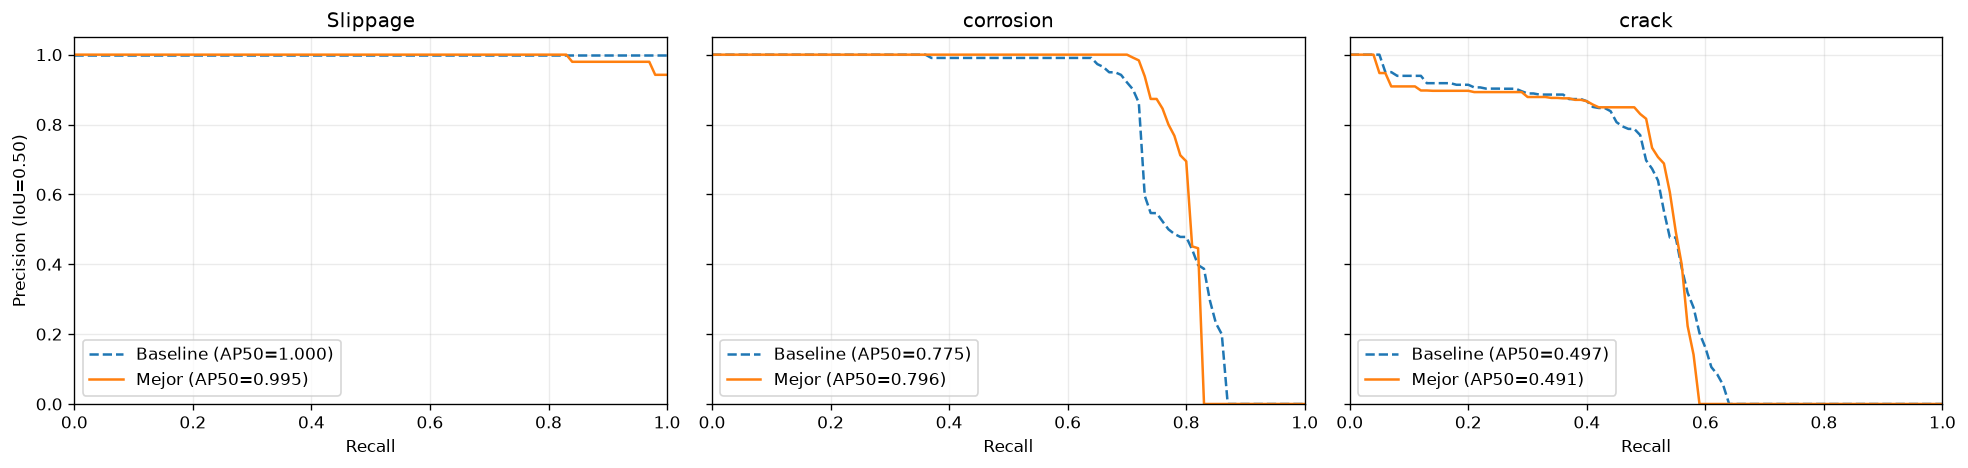

In [52]:
# Comparación PR y errores aproximados entre baseline y mejor configuración,
# seleccionada EXCLUSIVAMENTE con validación.
if metricas_por_exp:
    nombre_mejor = max(metricas_por_exp, key=lambda k: metricas_por_exp[k].get("map", -1))
    print(f"Mejor configuración en validation: {nombre_mejor} "
          f"(mAP={metricas_por_exp[nombre_mejor]['map']:.4f})")

    claves_err = ["TP", "Loc", "Cls", "Both", "Dup", "Bkg", "Miss"]
    exps_con_err = [n for n, m in metricas_por_exp.items() if "analisis_errores_05" in m]
    if exps_con_err:
        fig, ax = plt.subplots(figsize=(10.5, max(3.5, 0.6 * len(exps_con_err) + 1.2)))
        y = np.arange(len(exps_con_err))
        izquierda = np.zeros(len(exps_con_err))
        for clave in claves_err:
            valores = np.array([metricas_por_exp[n]["analisis_errores_05"].get(clave, 0)
                                for n in exps_con_err])
            ax.barh(y, valores, left=izquierda, label=clave)
            izquierda += valores
        ax.set_yticks(y)
        ax.set_yticklabels(exps_con_err)
        ax.invert_yaxis()
        ax.set_xlabel("Número de detecciones/instancias")
        ax.set_title("Errores aproximados (estilo TIDE, no análisis TIDE oficial)")
        ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.15))
        plt.tight_layout()
        plt.savefig(DIR_FIGURAS / "06_errores_validacion.png", bbox_inches="tight")
        plt.show()
    else:
        print("Para comparar tipos de errores, guarda metricas_validation.json con src.evaluar.")

    if (NOMBRE_BASELINE in metricas_por_exp
            and "curvas_pr_50" in metricas_por_exp[NOMBRE_BASELINE]
            and "curvas_pr_50" in metricas_por_exp[nombre_mejor]):
        curvas_base = metricas_por_exp[NOMBRE_BASELINE]["curvas_pr_50"]
        curvas_mejor = metricas_por_exp[nombre_mejor]["curvas_pr_50"]
        # Mostrar las clases para las que se guardaron curvas con anotaciones.
        clases_disponibles = [nombre for nombre in NOMBRES_CLASES.values()
                              if curvas_base.get(nombre, {}).get("n_gt", 0) > 0]
        if clases_disponibles:
            fig, axes = plt.subplots(1, len(clases_disponibles),
                                     figsize=(5.5 * len(clases_disponibles), 4), squeeze=False,
                                     sharey=True)
            for ax, nombre in zip(axes[0], clases_disponibles):
                b = curvas_base.get(nombre)
                m = curvas_mejor.get(nombre)
                if b and len(b.get("recall", [])) > 0:
                    ax.plot(b["recall"], b["precision_interp"], "--",
                            label=f"Baseline (AP50={b['ap']:.3f})")
                if nombre_mejor != NOMBRE_BASELINE and m and len(m.get("recall", [])) > 0:
                    ax.plot(m["recall"], m["precision_interp"], "-",
                            label=f"Mejor (AP50={m['ap']:.3f})")
                ax.set_title(nombre)
                ax.set_xlabel("Recall")
                ax.set_xlim(0, 1)
                ax.set_ylim(0, 1.05)
                if ax.lines:
                    ax.legend(loc="lower left")
            axes[0, 0].set_ylabel("Precision (IoU=0.50)")
            plt.tight_layout()
            plt.savefig(DIR_FIGURAS / "07_curvas_pr_comparativa_validation.png", bbox_inches="tight")
            plt.show()
    else:
        print("Faltan curvas PR detalladas para comparar baseline y mejor experimento.")
else:
    print("Sin experimentos evaluados todavía.")


### Curvas PR y errores de localización

A IoU 0,50, el AP de `crack` apenas cambia entre el baseline y el mejor E2 (0,4969 frente a 0,4912). A IoU 0,75, pasa de **0,0792 a 0,1139**. La ganancia con el umbral más exigente apunta a una mejor localización de las grietas.

Con confianza ≥ 0,50, E2 reduce los errores de localización de 18 a 13 y los falsos positivos de fondo de 17 a 11. Aun así, quedan **190 de las 472 anotaciones sin emparejar**. El desglose depende de ese umbral de confianza. Las curvas PR recorren las predicciones ordenadas por puntuación.

---
## 5. Análisis cualitativo y prueba de TTA

### Aciertos y fallos en validación

La figura muestra predicciones de **E2 a 960 px, checkpoint de la época 13**, con una sola vista. Las cajas verdes discontinuas son las anotaciones. Las cajas sólidas son predicciones con confianza ≥ 0,50. Azul indica `Slippage`, rojo indica `corrosion` y naranja indica `crack`.

Para elegir los ejemplos, se emparejan cajas de la misma clase con IoU ≥ 0,50. La fila superior muestra imágenes con alta proporción de aciertos. La inferior muestra imágenes con muchos falsos positivos o falsos negativos.


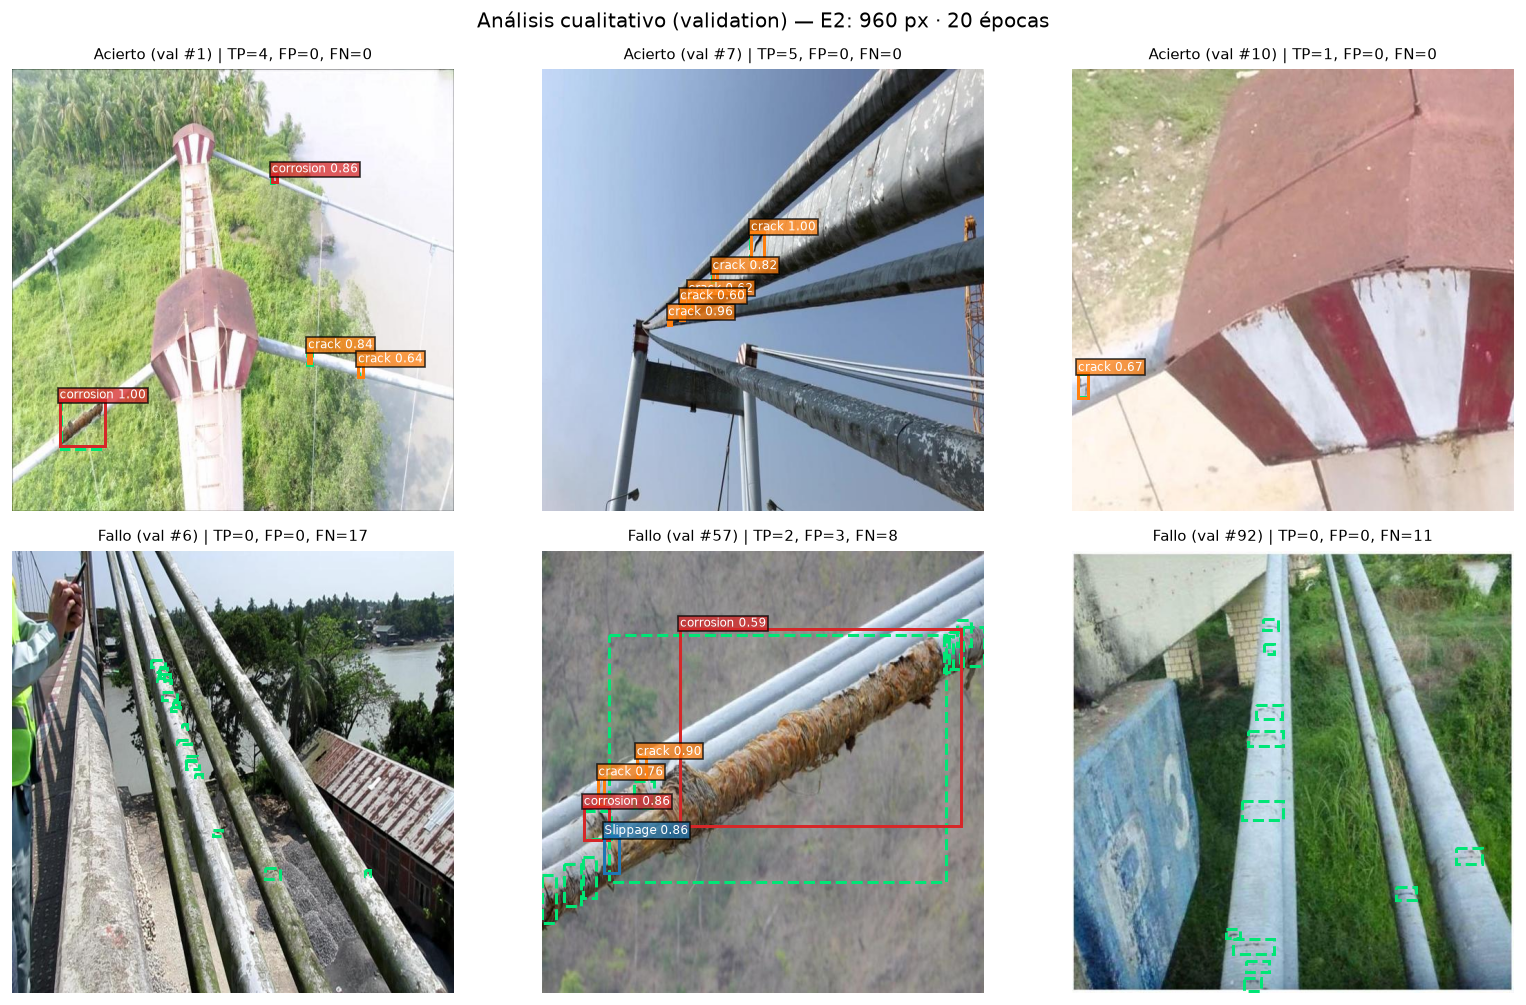

In [53]:
def dibujar_detecciones(ax, imagen_tensor, gt, pred, titulo="", score_thr=0.50):
    ax.imshow(imagen_tensor.permute(1, 2, 0).numpy())
    for caja, etq in zip(gt["boxes"].numpy(), gt["labels"].numpy()):
        x1, y1, x2, y2 = caja
        ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1,
                               fill=False, edgecolor="#00e676", linewidth=1.8, linestyle="--"))
    for caja, score, etq in zip(pred["boxes"].numpy(), pred["scores"].numpy(), pred["labels"].numpy()):
        if score < score_thr:
            continue
        x1, y1, x2, y2 = caja
        color = COLORES_CLASE.get(int(etq), "yellow")
        ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False,
                               edgecolor=color, linewidth=1.8))
        ax.text(x1, max(0, y1 - 3), f"{NOMBRES_CLASES.get(int(etq), str(etq))} {score:.2f}",
                color="white", fontsize=7,
                bbox={"facecolor": color, "alpha": 0.75, "pad": 1})
    ax.set_title(titulo, fontsize=9)
    ax.axis("off")


def clasificar_imagenes_cualitativo(ds, preds, score_thr=0.50):
    """Cuenta TP, FP y FN con emparejamiento uno-a-uno, clase e IoU>=0.5."""
    resumenes = []
    for idx in range(len(ds)):
        _, gt = ds[idx]
        pred = preds[idx]
        cajas_gt, clases_gt = gt["boxes"].numpy(), gt["labels"].numpy()
        mask = pred["scores"].numpy() >= score_thr
        cajas_p, clases_p = pred["boxes"].numpy()[mask], pred["labels"].numpy()[mask]
        scores_p = pred["scores"].numpy()[mask]

        usados = set()
        tp = 0
        if len(cajas_p) and len(cajas_gt):
            ious = _iou_entre_cajas(cajas_p, cajas_gt)
            for i in np.argsort(-scores_p):
                validos = [j for j in range(len(cajas_gt))
                           if j not in usados and clases_p[i] == clases_gt[j] and ious[i, j] >= 0.5]
                if validos:
                    j = max(validos, key=lambda j: ious[i, j])
                    usados.add(j)
                    tp += 1
        fn = len(cajas_gt) - tp
        fp = len(cajas_p) - tp
        resumenes.append({"idx": idx, "n_gt": len(cajas_gt), "tp": tp, "fp": fp, "fn": fn})
    return resumenes


# Elegir la mejor configuración SOLO según las métricas de validación.
ruta_preds_mejor = None
nombre_cual = None
for nombre in sorted(metricas_por_exp, key=lambda n: -metricas_por_exp[n].get("map", -1)):
    candidata = EXPERIMENTOS[nombre]["dir"] / "predicciones_validation.json"
    if candidata.exists():
        ruta_preds_mejor = candidata
        nombre_cual = nombre
        break

if ruta_preds_mejor is not None:
    ds_val = CorrosionDataset("validation")
    preds_cual = cargar_predicciones(ruta_preds_mejor)
    if len(preds_cual) != len(ds_val):
        print("Las predicciones guardadas no coinciden con el número de imágenes de validación.")
    else:
        stats = clasificar_imagenes_cualitativo(ds_val, preds_cual, score_thr=0.50)
        aciertos = sorted([s for s in stats if s["n_gt"] >= 1],
                          key=lambda s: (-s["tp"] / max(s["n_gt"], 1), s["fp"] + s["fn"]))[:3]
        fallos = sorted([s for s in stats if s["n_gt"] >= 1],
                        key=lambda s: -(s["fp"] + s["fn"]))[:3]
        fig, axes = plt.subplots(2, 3, figsize=(13.5, 8.5))
        for fila, grupo, tipo in [(0, aciertos, "Acierto"), (1, fallos, "Fallo")]:
            for col, ax in enumerate(axes[fila]):
                if col >= len(grupo):
                    ax.axis("off")
                    continue
                s = grupo[col]
                imagen, gt = ds_val[s["idx"]]
                dibujar_detecciones(
                    ax, imagen, gt, preds_cual[s["idx"]],
                    titulo=f"{tipo} (val #{s['idx']}) | TP={s['tp']}, FP={s['fp']}, FN={s['fn']}",
                )
        fig.suptitle(f"Análisis cualitativo (validation) — {nombre_cual}", fontsize=12)
        plt.tight_layout()
        plt.savefig(DIR_FIGURAS / "08_analisis_cualitativo_validation.png", bbox_inches="tight")
        plt.show()
else:
    print("No se encontró predicciones_validation.json. Genera predicciones con src.evaluar.")


En la imagen #7, E2 empareja las cinco grietas anotadas. En las imágenes #6 y #92, quedan 17 y 11 anotaciones sin emparejar, respectivamente, con el umbral de confianza usado para la figura. La imagen #57 combina ocho omisiones y tres falsos positivos. Estos ejemplos ayudan a entender por qué sigue habiendo margen de mejora en escenas con varios defectos pequeños.

### E5 · Inferencia con dos vistas

Se compara el **mismo checkpoint de E2** sobre las mismas 125 imágenes de validación. TTA procesa la vista original y el volteo horizontal, devuelve las cajas volteadas a las coordenadas originales y las fusiona por clase con WBF (IoU de fusión **0,55**).

La latencia se mide imagen a imagen para ambas variantes. Se excluye la primera imagen como calentamiento y se incluyen las transferencias entre CPU y GPU cuando corresponde y la fusión WBF en TTA. Si falta el checkpoint, consulta los pasos de entrenamiento en el [README](../README.md#retinanet-v2).

In [54]:
from time import perf_counter

from src.evaluar import cargar_modelo_desde_checkpoint, evaluar_predicciones
from src.postprocesado import predecir_imagen_tta

@torch.inference_mode()
def comparar_vista_retinanet(modelo_tta, datos_tta, dispositivo_tta, modalidad, usar_tta):
    predicciones, objetivos, duraciones = [], [], []

    for indice, (imagen, anotacion) in enumerate(datos_tta):
        if dispositivo_tta.type == "cuda":
            torch.cuda.synchronize()
        inicio = perf_counter()

        if usar_tta:
            prediccion = predecir_imagen_tta(
                modelo_tta,
                imagen,
                dispositivo_tta,
                modos=("original", "hflip"),
                iou_wbf=0.55,
            )
        else:
            imagen_gpu = imagen.to(dispositivo_tta)
            with torch.amp.autocast(
                device_type=dispositivo_tta.type,
                enabled=dispositivo_tta.type == "cuda",
            ):
                salida = modelo_tta([imagen_gpu])[0]
            prediccion = {
                "boxes": salida["boxes"].cpu().float(),
                "scores": salida["scores"].cpu().float(),
                "labels": salida["labels"].cpu(),
            }

        if dispositivo_tta.type == "cuda":
            torch.cuda.synchronize()
        if indice > 0:  # La primera imagen sirve de calentamiento.
            duraciones.append(perf_counter() - inicio)

        predicciones.append(prediccion)
        objetivos.append({
            clave: anotacion[clave] for clave in ("boxes", "labels", "image_id")
        })

    metricas = evaluar_predicciones(predicciones, objetivos, incluir_pr=True)
    return {
        "Inferencia": modalidad,
        "mAP@[0.50:0.95]": metricas["map"],
        "mAP_small": metricas["map_small"],
        "AP crack @ IoU 0.75": metricas["curvas_pr_75"]["crack"]["ap"],
        "ms/imagen": 1000 * sum(duraciones) / len(duraciones),
    }


ruta_checkpoint = DIR_RESULTADOS / "retinanet_exp02_resolucion_20ep" / "mejor_modelo.pth"
if ruta_checkpoint.is_file():
    dispositivo_tta = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    modelo_tta, _ = cargar_modelo_desde_checkpoint(ruta_checkpoint, dispositivo_tta)
    modelo_tta.eval()
    datos_tta = CorrosionDataset("validation")
    comparativa_tta = pd.DataFrame([
        comparar_vista_retinanet(modelo_tta, datos_tta, dispositivo_tta, "Original", usar_tta=False),
        comparar_vista_retinanet(modelo_tta, datos_tta, dispositivo_tta, "Original + hflip + WBF", usar_tta=True),
    ])
    display(comparativa_tta.round(4))
else:
    print(f"Se omite la prueba de TTA en validación: falta {ruta_checkpoint.relative_to(RAIZ)}.")
    print("Para generar el checkpoint, ejecuta desde la raíz del repositorio:")
    print("uv run --locked python -m src.entrenar --config configs/experimentos/retinanet_exp02_resolucion_20ep.yaml --sin-test")

,Inferencia,mAP@[0.50:0.95],mAP_small,AP crack @ IoU 0.75,ms/imagen
0,Original,0.4596,0.4376,0.1139,39.8162
1,Original + hflip + WBF,0.4686,0.4479,0.1368,77.4137


### Resultado y selección para test

En la ejecución de referencia, con TTA el **mAP subió de 0,4596 a 0,4686**, el de objetos pequeños pasó de 0,4376 a 0,4479 y el AP de `crack` a IoU 0,75 mejoró de 0,1139 a 0,1368. La latencia pasó de **39,82 a 77,41 ms por imagen**, un aumento aproximado del 94 %.

Según el criterio de mAP de validación, **E2 a 960 px con el checkpoint de la época 13 y TTA** es la configuración individual seleccionada. La inferencia de una sola vista con ese checkpoint sirve como referencia de menor latencia.

---
## 6. Ensemble RetinaNet v2 + Faster R-CNN v2 (Weighted Boxes Fusion)

La siguiente comparación es la fusión de RetinaNet con Faster R-CNN en validación. El ensemble combina predicciones de dos detectores. El TTA de la sección 5 combina dos vistas del mismo detector. Para el ensemble, comprueba que ambos archivos de predicciones contienen los mismos IDs de imagen en el mismo orden.

Una vez fijado el ensemble (incluidos pesos e IoU), la comparación final se puede ejecutar sobre `test`, por ejemplo:

```bash
uv run --locked python -m scripts.evaluar_postprocesado ensemble \
  --preds results/slippage_validation_split/faster_rcnn/predicciones_test.json results/slippage_validation_split/retinanet_exp02_resolucion_20ep/predicciones_test.json \
  --pesos 1.0 1.0 \
  --iou-wbf 0.55 \
  --salida results/slippage_validation_split/exp08_ensemble_wbf
```

Ajustad las rutas a los modelos finalmente seleccionados. **No optimicéis los hiperparámetros del ensemble mirando su puntuación de test.**


---
## 7. Evaluación final en `test` (una vez elegidos los modelos)

Esta sección **no participa en la selección de experimentos**. Solo presenta resultados finales si ya los habéis calculado.

La configuración individual seleccionada por mAP es E2 a 960 px con TTA. La [guía de reproducción del README](../README.md#retinanet-v2) incluye los dos comandos de test para el mismo checkpoint de la época 13, con una vista o con la vista original y el volteo horizontal fusionados mediante WBF a IoU 0,55.

En la ejecución de referencia, la latencia de vista única (34,21 ms/img) se midió en lotes de cuatro, cronometrando el pase del modelo y omitiendo el primer lote. La de TTA (76,78 ms/img) se midió imagen a imagen, incluyendo transferencias y WBF y omitiendo la primera imagen. La sección 5 contiene la comparación de latencia bajo un protocolo común.

In [55]:
# Mostrar resultados finales de test únicamente cuando existan.
# No elegir aquí qué experimento es el mejor: la elección ya se hizo en validación.
filas_test = []
experimentos_test = {
    **EXPERIMENTOS,
    "E2: 960 px · 20 épocas + TTA": {
        "dir": DIR_RESULTADOS / "retinanet_exp02_resolucion_20ep_tta",
    },
}
for nombre, meta in experimentos_test.items():
    ruta_final = meta["dir"] / "metricas_test_final.json"
    if ruta_final.exists():
        m = leer_json(ruta_final)
    else:
        m = cargar_metricas_experimento(meta["dir"], "test")
    if not isinstance(m, dict) or "map" not in m:
        continue
    ap_clase = m.get("map_por_clase", {})
    filas_test.append({
        "Experimento (test final)": nombre,
        "mAP@0.50:0.95": m.get("map", np.nan),
        "mAP@0.50": m.get("map_50", np.nan),
        "mAP_small": m.get("map_small", np.nan),
        "AP Slippage": ap_clase.get("Slippage", np.nan),
        "AP corrosion": ap_clase.get("corrosion", np.nan),
        "AP crack": ap_clase.get("crack", np.nan),
        "ms/img": m.get("tiempos", {}).get("ms_por_imagen", np.nan),
    })

if filas_test:
    print("Resultados finales en test (no usar para elegir hiperparámetros):")
    display(pd.DataFrame(filas_test).round(4))
else:
    print("Todavía no hay métricas finales de test. Es correcto durante el desarrollo.")

Resultados finales en test (no usar para elegir hiperparámetros):


,Experimento (test final),mAP@0.50:0.95,mAP@0.50,mAP_small,AP Slippage,AP corrosion,AP crack,ms/img
0,E2: 960 px · 20 épocas,0.4277,0.7051,0.4006,0.6505,0.3373,0.2955,34.21
1,E2: 960 px · 20 épocas + TTA,0.4348,0.7150,0.4060,0.6531,0.3462,0.3051,76.78
